In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths

In [2]:
df = pd.read_csv('Opto_ScoreIntZones.csv')

#df = df.drop(2)
df = df.drop('Cups Hab', 1)
print(df)


    Group  Cups LTM       LTM Control
0       1  0.161834 -0.350335       n
1       2 -0.053594  0.415937       n
2       3 -0.124809 -0.145149       n
3       4 -0.070433  0.544060       y
4       5 -0.078295  0.000000       n
5       6  0.163636 -0.100000       n
6       7  0.150000  0.480000       n
7       8 -0.058278  0.369565       y
8       9 -0.059813  0.100000       n
9      10 -0.243128 -0.173210       y
10     11  0.105227  0.197765       n
11     12 -0.079821 -0.016904       n
12     13 -0.232323  0.407407       y
13     14 -0.131222  0.040000       y
14     15  0.071521  0.119650       n
15     16 -0.070288 -0.062585       n
16     17  0.163121  0.700000       y
17     18 -0.050000  0.123000       y
18     19  0.242222  0.789919       y
19     20  0.100000  0.350000       n
20     21  0.024958 -0.400000       y
21     22  0.089342  0.512440       y
22     23  0.197765  0.042518       n
23     24 -0.016904 -0.031560       n


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_40639/2034556524.py:4: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only.
  df = df.drop('Cups Hab', 1)


In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


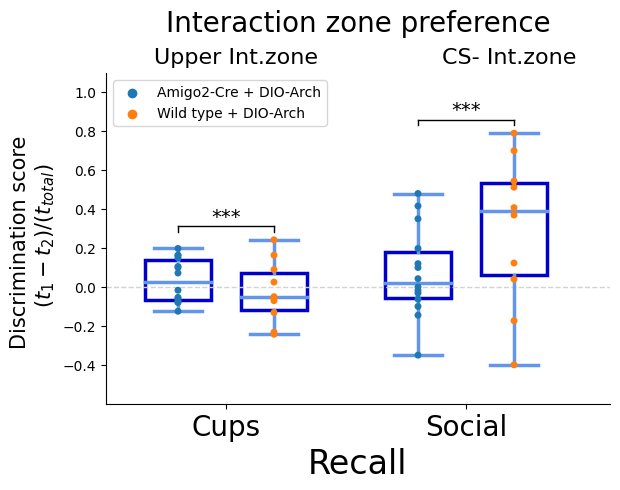

In [4]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue'},
    'medianprops':{'color':'cornflowerblue'},
    'whiskerprops':{'color':'cornflowerblue'},
    'capprops':{'color':'cornflowerblue'}
}

text_boxplot = ['***','***']
sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    jitter=0,
    dodge=True
).axhline(linewidth=1, color='lightgrey',ls='--')
#plt.axvline(x=0.5,linewidth=1, color='red',ls='--')

#axvline(x=1.5,linewidth=1, color='red',ls='--') -- how to add in addition?
ax = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette="Set3",
    fliersize=0,
    linewidth=2.5,
    **PROPS
)
data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["Amigo2-Cre + CNO", "Wild type + CNO"], loc=2)
l = plt.legend(handles[0:2],  ["Amigo2-Cre + DIO-Arch", "Wild type + DIO-Arch"]  , loc=2)


#ax.text(-0.4,1.15,'Upper Int.zone', fontsize = 12)
#ax.text(0.8,1.15,'CS- Int.zone', fontsize = 12)

#ax.set_xlabel("Female cohort",fontsize=15)

ax.set_ylabel("Preference ratio",fontsize=15)
ax.set_ylabel('Discrimination score \n $(t_{1}-t_{2})/(t_{total})$')

ax.set_xticklabels(['Cups','Social'], fontsize = 20)
ax.text(-0.3,1.15,'Upper Int.zone', fontsize = 16)
ax.text(0.9,1.15,'CS- Int.zone', fontsize = 16)
ax.set_xlabel("Recall",fontsize=24)

ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.5,1.6])
plt.title("Interaction zone preference", fontsize=20,y=1.1)

significance(ax,0,data_ratio,newdf.loc[newdf['Experimental Condition']=='Cups LTM']['Left preference'].max(),text=text_boxplot[0])
significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

fig = ax.get_figure()

adjust_box_widths(fig, 0.7)
fig.set_size_inches(6.3,5)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig6OptInt.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig6OptInt.eps', format='eps')





In [5]:
newdf

,Experimental Condition,Left preference,control
0,Cups LTM,0.161834,n
1,Cups LTM,-0.053594,n
2,Cups LTM,-0.124809,n
3,Cups LTM,-0.070433,y
4,Cups LTM,-0.078295,n
5,Cups LTM,0.163636,n
6,Cups LTM,0.150000,n
7,Cups LTM,-0.058278,y
8,Cups LTM,-0.059813,n
9,Cups LTM,-0.243128,y
